# 03 · K-fold cross-validation with nine rows

**The problem.** If you check a guess on one small group, that group
could be especially easy or hard. How could we check several groups?

**The example.** Take nine apartments recorded on the same day and
divide them into three blocks. The k in k-fold means how many blocks
we make. Each block is called a fold.

**Why we use it.** Rotating the validation block lets each row help check
a guess once. The errors across blocks show how much results can vary.

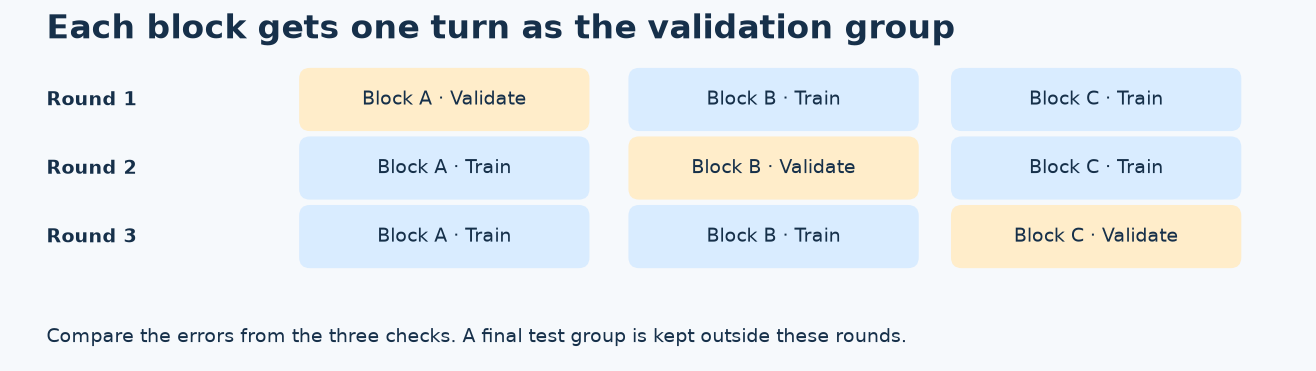

## 1 · Open nine examples from one date

**What we’re doing.** Find nine Dubai apartment valuations from 15 January 2024.

**Why we’re doing it.** Using one date makes it easy to focus on the rotating groups. For forecasts, keep earlier rows before later ones.

**What to look for.** Block A contains rows 1–3, B has rows 4–6, and C has rows 7–9.

In [1]:
import pandas as pd
from IPython.display import display
from sklearn.model_selection import KFold

from pathlib import Path

current_folder = Path.cwd()
data_folder = next(
    (folder / "data" for folder in (current_folder, *current_folder.parents)
     if (folder / "data" / "property_valuations.csv").is_file()),
    None,
)
if data_folder is None:
    raise FileNotFoundError("Open the extracted course folder in Jupyter or VS Code.")

columns = ["valuation_date", "property_type", "emirate", "size_sqft", "valuation_aed"]
properties = pd.read_csv(data_folder / "property_valuations.csv", usecols=columns, parse_dates=["valuation_date"])
dubai = properties[properties["emirate"] == "Dubai"]
dubai = dubai.query("size_sqft > 0 and valuation_aed > 0")
apartments = dubai[dubai["property_type"] == "Apartment"]

sample = apartments[apartments["valuation_date"] == "2024-01-15"].head(9).reset_index(drop=True)
sample["row"] = range(1, 10)
sample["block"] = ["A", "A", "A", "B", "B", "B", "C", "C", "C"]
sample[["row", "block", "size_sqft", "valuation_aed"]]

,row,block,size_sqft,valuation_aed
0,1,A,1124.0,692000.0
1,2,A,537.0,531000.0
2,3,A,501.0,542000.0
3,4,B,1561.0,2210000.0
4,5,B,1731.0,2679000.0
5,6,B,350.0,325000.0
6,7,C,1148.0,1666000.0
7,8,C,1775.0,2627000.0
8,9,C,929.0,1797000.0


## 2 · Do the first round by hand

**What we’re doing.** Use the middle value from B and C, then calculate the misses on A.

**Why we’re doing it.** This keeps group A out of the calculation of the guess. A is used only to check the result on this round.

**What to look for.** The three misses are in AED. Their average is the first round’s error.

In [2]:
learn_from = sample[sample["block"] != "A"]
check_on = sample[sample["block"] == "A"]
guess = learn_from["valuation_aed"].median()
misses = (check_on["valuation_aed"] - guess).abs()
print("Three misses in AED:", misses.tolist())
print(f"Round 1 · average miss AED {misses.mean():,.0f}")

Three misses in AED: [1311500.0, 1472500.0, 1461500.0]
Round 1 · average miss AED 1,415,167


## 3 · Rotate the block and compare

**What we’re doing.** Let KFold rotate the held-out block and show three rounds in a single table.

**Why we’re doing it.** The score from just one group can be misleading. Three checks show both the typical score and how much it changes.

**What to look for.** Each block appears once under Validate on. The first error matches the hand calculation.

In [3]:
results = []
for train_rows, validation_rows in KFold(n_splits=3).split(sample):
    train = sample.iloc[train_rows]
    validate = sample.iloc[validation_rows]
    guess = train["valuation_aed"].median()
    error = (validate["valuation_aed"] - guess).abs().mean()
    results.append([", ".join(train["block"].unique()), validate["block"].iloc[0], error])

scores = pd.DataFrame(results, columns=["Train on", "Validate on", "Average miss (AED)"])
display(scores.round(0))
print(f"Average over all three rounds: AED {scores['Average miss (AED)'].mean():,.0f}")

,Train on,Validate on,Average miss (AED)
0,"B, C",A,1415167.0
1,"A, C",B,1128333.0
2,"A, B",C,1413000.0


Average over all three rounds: AED 1,318,833


**Connect this to D2.1.** In each round we used a median guess so we could
focus on the split. You can fit a model in the same training blocks and
compare methods using the validation results. Save the final test rows
for after you choose.

**Two uses of k.** In KNN, k is how many nearby examples vote. In k-fold,
k is how many groups take turns being the validation group. The usual
name for the second process is **k-fold cross-validation**.